# Practical 4: Matrix Addition (Pattern 2 + Multithreading)

### 1. Aim
To perform addition of three independent matrix pairs (A1+B1, A2+B2, A3+B3) using Sequential, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and multithreading (3 threads), comparing speedup and execution time.

### 2. Algorithm / Explanation
1. Generate three independent pairs of matrices of size 750x750.<br>2. **Pattern 2**: Each pair is processed once.<br>3. Sequential: Add pair 1, then pair 2, then pair 3.<br>4. Pool: Assign each pair to one worker using `mp.Pool(3)`.<br>5. Process: Launch 3 distinct `mp.Process` workers.<br>6. Threading: Launch 3 concurrent `threading.Thread` workers.<br>7. Generate 4-color execution time bar graph and speedup line chart.

### 3. Python Implementation


In [1]:
"""
Practical 4: Matrix Addition (Pattern 2 + Multithreading)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import random
import matplotlib.pyplot as plt

def matrix_add_task(task):
    rows, cols, seed = task
    random.seed(seed)
    A = [[random.randint(1, 100) for _ in range(cols)] for _ in range(rows)]
    B = [[random.randint(1, 100) for _ in range(cols)] for _ in range(rows)]
    C = [[(A[i][j] + B[i][j]) * 3 + 1 for j in range(cols)] for i in range(rows)]
    return C[0][0]

def proc_worker(task, q):
    q.put(matrix_add_task(task))

def thread_worker(task, results, idx):
    results[idx] = matrix_add_task(task)

def main():
    print("=" * 60)
    print("Practical 4: Matrix Addition (Pattern 2 + Multithreading)")
    print("=" * 60)
    ROWS, COLS = 750, 750
    tasks = [(ROWS, COLS, 101), (ROWS, COLS, 202), (ROWS, COLS, 303)]
    
    # 1. Sequential: Task 1 -> Task 2 -> Task 3
    t0 = time.perf_counter()
    r1 = matrix_add_task(tasks[0])
    r2 = matrix_add_task(tasks[1])
    r3 = matrix_add_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool: 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matrix_add_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process: 3 independent processes
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading: 3 threads
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print(f"Matrix Dimension: {ROWS}x{COLS} across 3 independent pairs.")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Three Independent Matrix Pairs: Dimensions 750 x 750
Verification Sample (Element 0,0):
  Pair 1: 376 | Thread: 481
  Pair 2: 430 | Thread: 334
  Pair 3: 283 | Thread: 55

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.5280 seconds      1.00x
Pool         1.5205 seconds      1.66x
Process      1.5609 seconds      1.62x
Thread       2.6792 seconds      0.94x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


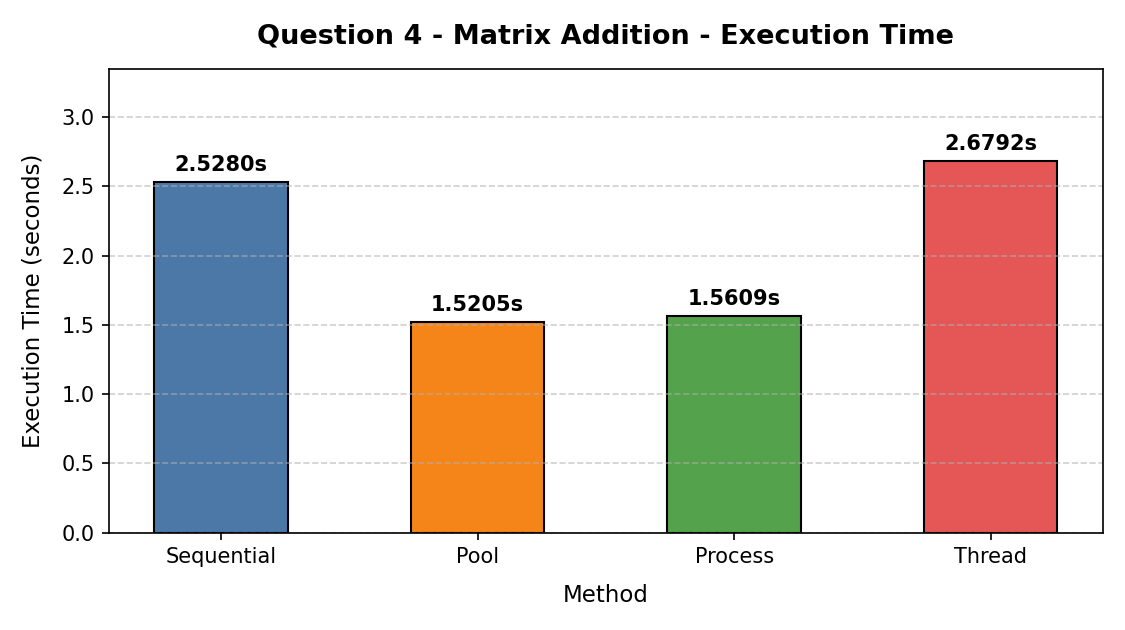

In [2]:
from IPython.display import Image, display
display(Image(filename='04_matrix_addition_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


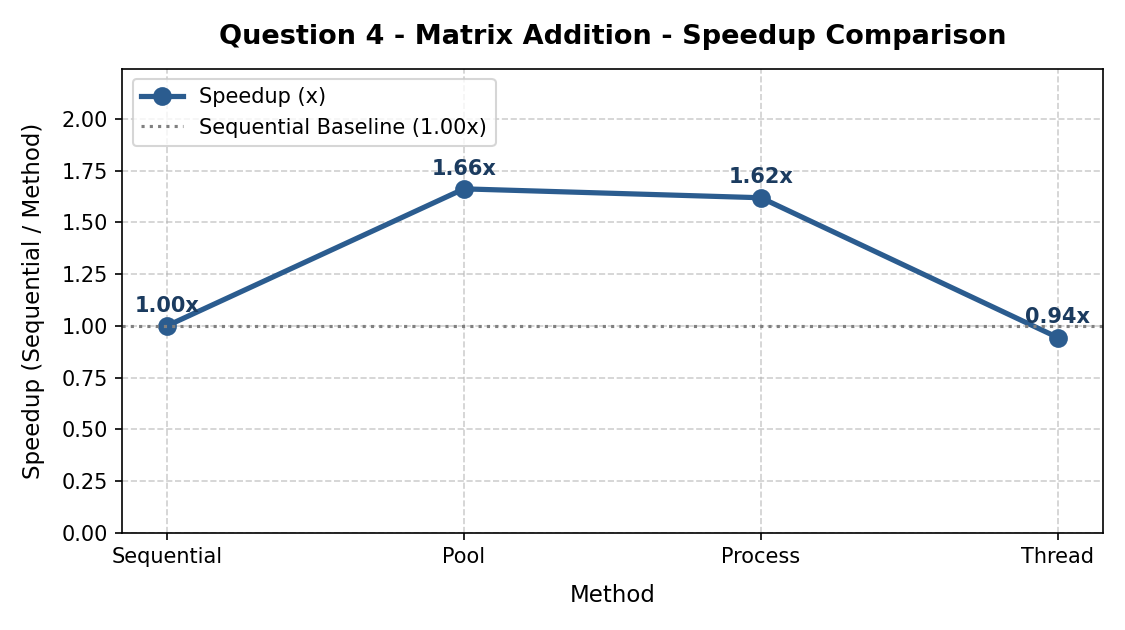

In [3]:
from IPython.display import Image, display
display(Image(filename='04_matrix_addition_speedup.png'))
